# Tuning curves and population codes

How does a pattern of spikes represent the world? This notebook works through the standard
answers in order: a single neuron's **tuning curve** and its noise; how to find what a neuron
responds to; and how a **population** of noisy, broadly tuned neurons can be read out precisely.
It closes with a population that represents **duration**, and shows how Weber's law for timing
can fall out of the way the code is laid out.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
rng = np.random.default_rng(0)

## Encoding and decoding

**Encoding** asks how a stimulus $s$ produces a response $\mathbf r$: the distribution
$P(\mathbf r \mid s)$. **Decoding** goes the other way, from responses to an estimate of the
stimulus, and Bayes' rule links the two:

$$P(s \mid \mathbf r) = \frac{P(\mathbf r \mid s)\,P(s)}{P(\mathbf r)} .$$

Neurons use several codes. In a **rate code** the spike count in a window carries the
information; in a **latency code** the time of the first spike does; in a **population code**
the information is distributed across many neurons. We focus on rate and population codes.

## Tuning curves and Poisson noise

A tuning curve $f(s)$ gives a neuron's mean firing rate as a function of a stimulus variable.
Georgopoulos et al. (1982) found that neurons in monkey motor cortex are broadly tuned to reach
direction, roughly as a rectified cosine around a *preferred direction* $s_{\text{pref}}$:

$$f(s) = r_0 + r_{\max}\,\big[\cos(s - s_{\text{pref}})\big]_+ .$$

Repeated presentations of the same stimulus give different spike counts. A common model is
Poisson: the count in a window of length $T$ has mean and variance both equal to $f(s)\,T$, so
the **Fano factor** (variance / mean) is 1.

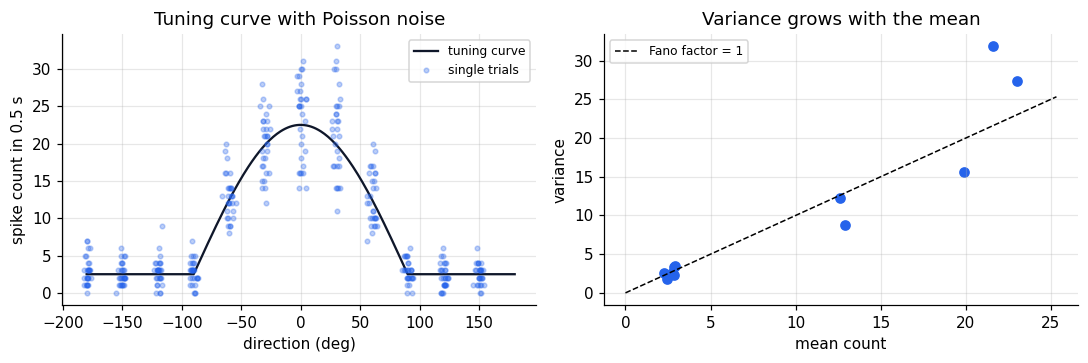

In [2]:
def cosine_tuning(s, pref, r0=5.0, rmax=40.0):
    return r0 + rmax * np.maximum(0, np.cos(s - pref))

T_win = 0.5
s_grid = np.linspace(-np.pi, np.pi, 361)
directions = np.deg2rad(np.arange(-180, 180, 30))
counts = rng.poisson(cosine_tuning(directions, 0.0)[:, None] * T_win, size=(len(directions), 30))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].plot(np.rad2deg(s_grid), cosine_tuning(s_grid, 0.0) * T_win, color="#0f172a", label="tuning curve")
axes[0].plot(np.repeat(np.rad2deg(directions), 30) + rng.normal(0, 2, counts.size), counts.ravel(),
             ".", alpha=0.3, color="#2563eb", label="single trials")
axes[0].set(xlabel="direction (deg)", ylabel="spike count in 0.5 s", title="Tuning curve with Poisson noise")
axes[0].legend(fontsize=8)
axes[1].scatter(counts.mean(1), counts.var(1, ddof=1), color="#2563eb")
lim = counts.mean(1).max() * 1.1
axes[1].plot([0, lim], [0, lim], "k--", lw=1, label="Fano factor = 1")
axes[1].set(xlabel="mean count", ylabel="variance", title="Variance grows with the mean")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Because variance grows with the mean, a single neuron is a poor messenger: its count at one
direction overlaps heavily with its count at neighbouring directions, and on the flat part of
the curve it carries no information at all.

## What does a neuron respond to? Spike-triggered averaging

For a time-varying stimulus, a widely used description is the **linear-nonlinear-Poisson** (LNP)
model: the stimulus is filtered by a linear temporal (or spatiotemporal) receptive field $k$,
passed through a static nonlinearity, and used as the rate of a Poisson process.

If the stimulus is white noise, the average stimulus history preceding a spike, the
**spike-triggered average** (STA), recovers the shape of $k$. We simulate a neuron with a
biphasic temporal filter, like many retinal and thalamic cells, and recover it.

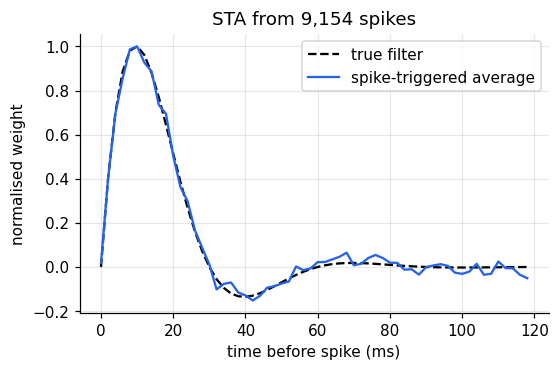

In [3]:
dt, n_steps, n_lags = 0.002, 300_000, 60
lags = np.arange(n_lags) * dt * 1000          # ms
true_k = (np.exp(-lags / 15) * np.sin(2 * np.pi * lags / 60))
true_k /= np.linalg.norm(true_k)

stim = rng.normal(0, 1, n_steps)
drive = np.convolve(stim, true_k, mode="full")[:n_steps]   # linear stage
rate = 20 * np.exp(1.2 * drive - 1.0)                       # nonlinearity (Hz)
spikes = rng.poisson(rate * dt)                             # Poisson spiking

spike_idx = np.flatnonzero(spikes[n_lags:]) + n_lags
sta = np.zeros(n_lags)
for lag in range(n_lags):
    sta[lag] = np.sum(stim[spike_idx - lag] * spikes[spike_idx])
sta /= spikes[spike_idx].sum()

fig, ax = plt.subplots(figsize=(5.5, 3.3))
ax.plot(lags, true_k / np.abs(true_k).max(), "k--", label="true filter")
ax.plot(lags, sta / np.abs(sta).max(), color="#2563eb", label="spike-triggered average")
ax.set(xlabel="time before spike (ms)", ylabel="normalised weight",
       title=f"STA from {spikes.sum():,} spikes")
ax.legend()
plt.show()

The STA matches the filter: this neuron fires when the stimulus was positive about 10 ms
earlier and slightly negative about 40 ms earlier, so it responds best to *increases*, a
temporal edge detector. In two spatial dimensions the same method maps centre-surround receptive fields in the
retina and oriented ones in V1 (notebook 7).

## Reading out a population

Now take $N$ neurons with preferred directions spread around the circle. A single trial gives a
vector of spike counts $\mathbf r$. Three ways to decode the direction:

**Population vector** (Georgopoulos). Each neuron votes for its preferred direction, weighted by
its rate above baseline; the estimate is the direction of the vector sum.

**Maximum likelihood.** With independent Poisson neurons the log-likelihood of direction $s$ is

$$\log P(\mathbf r \mid s) = \sum_i \big[r_i \log f_i(s) - f_i(s)\,T\big] + \text{const},$$

a weighted sum of the log tuning curves. Choose the $s$ that maximises it.

**Bayesian.** Multiply the likelihood by a prior and normalise to get the full posterior
$P(s \mid \mathbf r)$. Its width says how certain the population is on this trial.

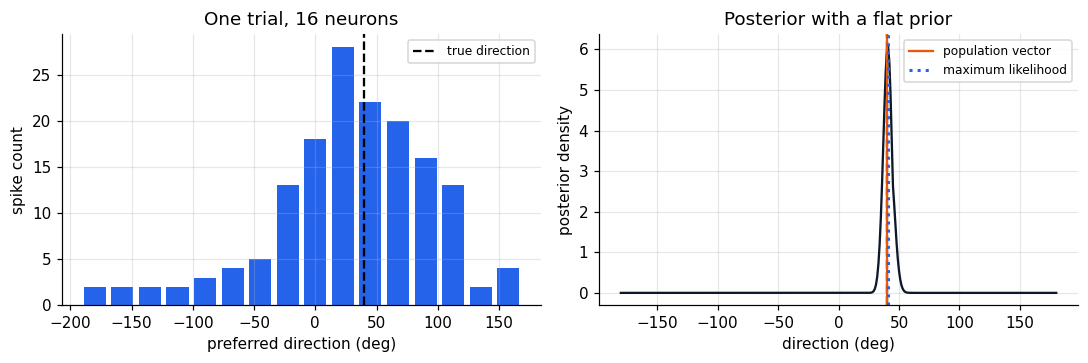

In [4]:
def population(N):
    return np.linspace(-np.pi, np.pi, N, endpoint=False)

def responses(s, prefs, n_trials=1, T=T_win):
    return rng.poisson(cosine_tuning(s, prefs) * T, size=(n_trials, len(prefs)))

def decode_pv(r, prefs, r0=5.0, T=T_win):
    w = np.maximum(r - r0 * T, 0)
    return np.arctan2(w @ np.sin(prefs), w @ np.cos(prefs))

def log_likelihood(r, prefs, T=T_win):
    F = cosine_tuning(s_grid[:, None], prefs[None, :]) * T     # grid × neurons
    return r @ np.log(F).T - F.sum(1)                          # trials × grid

def decode_ml(r, prefs):
    return s_grid[np.argmax(log_likelihood(r, prefs), axis=1)]

prefs = population(16)
s_true = np.deg2rad(40)
r = responses(s_true, prefs)
ll = log_likelihood(r, prefs)[0]
posterior = np.exp(ll - ll.max())
posterior /= posterior.sum() * (s_grid[1] - s_grid[0])

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].bar(np.rad2deg(prefs), r[0], width=18, color="#2563eb")
axes[0].axvline(40, color="k", ls="--", label="true direction")
axes[0].set(xlabel="preferred direction (deg)", ylabel="spike count", title="One trial, 16 neurons")
axes[0].legend(fontsize=8)
axes[1].plot(np.rad2deg(s_grid), posterior, color="#0f172a")
axes[1].axvline(40, color="k", ls="--")
axes[1].axvline(np.rad2deg(decode_pv(r[0], prefs)), color="#ea580c", label="population vector")
axes[1].axvline(np.rad2deg(decode_ml(r, prefs)[0]), color="#2563eb", ls=":", lw=2, label="maximum likelihood")
axes[1].set(xlabel="direction (deg)", ylabel="posterior density", title="Posterior with a flat prior")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## How precise is the code?

Decode many trials and measure the error as the population grows. For an unbiased decoder the
variance cannot fall below the **Cramér-Rao bound** $1/I_F(s)$, where for independent Poisson
neurons the Fisher information is

$$I_F(s) = T \sum_i \frac{f_i'(s)^2}{f_i(s)} .$$

Neurons contribute most where their tuning curves are steep, not where they fire most.

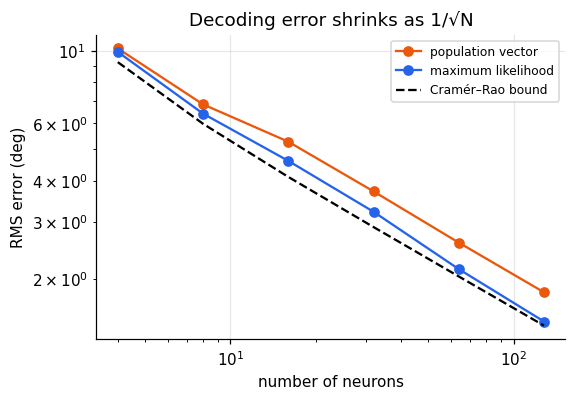

[[10.17  9.93  9.23]
 [ 6.86  6.42  5.98]
 [ 5.27  4.6   4.11]
 [ 3.71  3.21  2.89]
 [ 2.59  2.14  2.04]
 [ 1.82  1.48  1.44]]


In [5]:
def circ_err(a, b):
    return np.angle(np.exp(1j * (a - b)))

def fisher_info(s, prefs, T=T_win, eps=1e-4):
    f = cosine_tuning(s, prefs)
    df = (cosine_tuning(s + eps, prefs) - cosine_tuning(s - eps, prefs)) / (2 * eps)
    return T * np.sum(df ** 2 / f)

Ns = [4, 8, 16, 32, 64, 128]
rows = []
for N in Ns:
    prefs = population(N)
    s = rng.uniform(-np.pi, np.pi, 400)
    R = np.vstack([responses(si, prefs) for si in s])
    rows.append((np.rad2deg(np.sqrt(np.mean(circ_err(np.array([decode_pv(ri, prefs) for ri in R]), s) ** 2))),
                 np.rad2deg(np.sqrt(np.mean(circ_err(decode_ml(R, prefs), s) ** 2))),
                 np.rad2deg(np.sqrt(np.mean([1 / fisher_info(si, prefs) for si in s])))))
rows = np.array(rows)

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.loglog(Ns, rows[:, 0], "o-", color="#ea580c", label="population vector")
ax.loglog(Ns, rows[:, 1], "o-", color="#2563eb", label="maximum likelihood")
ax.loglog(Ns, rows[:, 2], "k--", label="Cramér-Rao bound")
ax.set(xlabel="number of neurons", ylabel="RMS error (deg)", title="Decoding error shrinks as 1/√N")
ax.legend(fontsize=8)
plt.show()
print(np.round(rows, 2))

Maximum likelihood reaches the bound once the population is moderately large; the population
vector is simple and robust but less efficient. With independent noise, error falls as
$1/\sqrt N$, so 16 neurons, each individually vague, already locate the direction within a few
degrees. In real cortex, noise correlations between neurons limit how far this improvement
goes.

## Uncertainty in the gain

Halve the observation window or the firing rates and every neuron emits fewer spikes. The
posterior widens. For Poisson-like variability the overall response amplitude, the **gain**,
therefore encodes how reliable the current evidence is, without any extra machinery. This is
the idea behind *probabilistic population codes* (Ma, Beck, Latham & Pouget, 2006), which let
downstream areas combine cues optimally (for example in multisensory integration) by adding
spike counts.

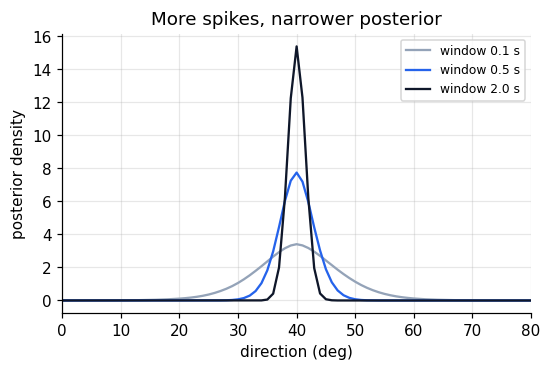

In [6]:
prefs = population(32)
fig, ax = plt.subplots(figsize=(5.5, 3.3))
for T_obs, color in [(0.1, "#94a3b8"), (0.5, "#2563eb"), (2.0, "#0f172a")]:
    post = np.zeros_like(s_grid)
    for _ in range(200):   # average over trials, recentred on the truth
        ll = log_likelihood(responses(s_true, prefs, T=T_obs), prefs, T=T_obs)[0]
        p = np.exp(ll - ll.max())
        p /= p.sum()
        shift = np.argmax(p) - np.argmin(np.abs(s_grid - s_true))
        post += np.roll(p, -shift)
    ax.plot(np.rad2deg(s_grid), post / 200 / (s_grid[1] - s_grid[0]), color=color,
            label=f"window {T_obs} s")
ax.set(xlim=(0, 80), xlabel="direction (deg)", ylabel="posterior density",
       title="More spikes, narrower posterior")
ax.legend(fontsize=8)
plt.show()

## A population for duration

Neurons tuned to specific durations have been found in several areas, including the
supplementary motor area of monkeys and, with fMRI, human parietal and premotor cortex.
Suppose their preferred durations are spaced evenly on a **logarithmic** scale, each with the
same Gaussian width in log time. Short durations then get many narrowly tuned neurons, long
durations few broad ones.

Decoding such a population with maximum likelihood and measuring the discrimination threshold
at each duration shows what this layout implies.

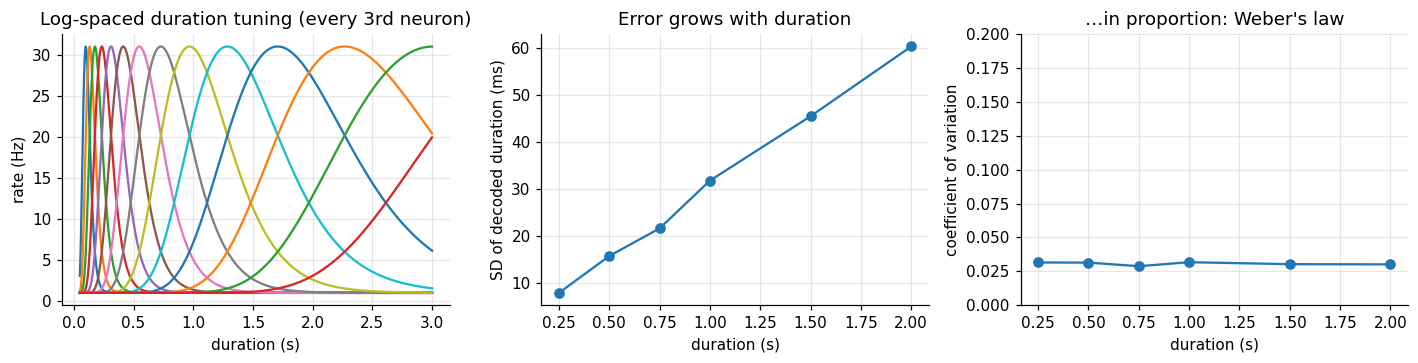

CV per duration: [0.032 0.031 0.029 0.032 0.03  0.03 ]


In [7]:
log_prefs = np.linspace(np.log(0.1), np.log(4.0), 40)
width, peak, base, T_dur = 0.3, 30.0, 1.0, 0.5

def duration_tuning(d):
    return base + peak * np.exp(-(np.log(d)[..., None] - log_prefs) ** 2 / (2 * width ** 2))

d_grid = np.exp(np.linspace(np.log(0.08), np.log(5.0), 1200))
F_grid = duration_tuning(d_grid) * T_dur

def decode_duration(R):
    ll = R @ np.log(F_grid).T - F_grid.sum(1)
    return d_grid[np.argmax(ll, axis=1)]

test_d = np.array([0.25, 0.5, 0.75, 1.0, 1.5, 2.0])
sd = []
for d in test_d:
    R = rng.poisson(duration_tuning(np.array([d]))[0] * T_dur, size=(1000, len(log_prefs)))
    sd.append(decode_duration(R).std())
sd = np.array(sd)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
dd = np.linspace(0.05, 3, 600)
axes[0].plot(dd, duration_tuning(dd)[:, ::3])
axes[0].set(xlabel="duration (s)", ylabel="rate (Hz)", title="Log-spaced duration tuning (every 3rd neuron)")
axes[1].plot(test_d, sd * 1000, "o-")
axes[1].set(xlabel="duration (s)", ylabel="SD of decoded duration (ms)", title="Error grows with duration")
axes[2].plot(test_d, sd / test_d, "o-")
axes[2].set(xlabel="duration (s)", ylabel="coefficient of variation", ylim=(0, 0.2),
            title="…in proportion: Weber's law")
plt.tight_layout()
plt.show()
print("CV per duration:", np.round(sd / test_d, 3))

The decoding error grows linearly with duration, so its coefficient of variation is constant:
the **scalar property** of interval timing, Weber's law for time. Nothing about timing was built
in except that the code is uniform in log duration. (The absolute CV here, about 3%, is far
below the 10-20% typical of human timing because the only noise in the model is Poisson
spiking in 40 independent neurons; the point is that the CV is constant, not its value.) Equivalent accounts place the log
compression elsewhere (in the internal clock, or in a Bayesian observer's prior), and telling
them apart is one of the open questions behind the experiments in notebooks 1-4.

## Summary

- A tuning curve gives mean rate as a function of the stimulus; Poisson variability makes the
  variance grow with the mean.
- The spike-triggered average recovers a neuron's linear receptive field from white-noise
  stimulation.
- Populations can be decoded by population vector, maximum likelihood, or a full Bayesian
  posterior; ML approaches the Cramér-Rao bound and error falls as $1/\sqrt N$.
- With Poisson-like noise, response gain encodes uncertainty.
- Uniform tuning on a log-duration axis produces Weber's law for time.